# Group 9 — Presentation II
**Where in the World Do Video Games Sell?** · Hollymay, Demana, Noah, Sam



| Section | What it does |
|---|---|
| 0 | Setup and config |
| 1 | Load the cleaned data and re-run the cleaning checks |
| 2 | Why we log-transform sales (figure) |
| 3 | One shared train/test split for every model |
| 4 | Helper functions (metrics, CV) |
| 5 | **RQ1**: Global sales from Genre + Publisher |
| 6 | **RQ2**: NA sales from EU + JP sales |
| 7 | Optional extension: classifying "hit" games (≥ 1m copies) | 
| 8 | Summary tables for the slides |
| 9 | Week 9: neural network vs random forest, K-means market clusters |

We used the 
VGData_Cleaned.xlsx` dataset

**Rules we follow:**
1. Split first. All imputation, encoding and scaling live inside a `Pipeline`, so they are fitted on training data only.
2. Compare models with 5-fold cross-validation on the **training** set.
3. Touch the **test set once**, only for the final chosen model.
4. Always compare against a **baseline** that predicts the mean.

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score)

# ---- Config: change DATA_PATH if your file lives elsewhere ----
DATA_PATH = "VGData_Cleaned.xlsx"
RANDOM_STATE = 42
TEST_SIZE = 0.2
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

KF = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight", dpi=200)

## 1. Load the cleaned data and recheck it
some `Platform` values (e.g. `2600`) load as numbers, which breaks the encoder, so we force every label to text.

In [2]:
df = pd.read_excel(DATA_PATH)

for col in ["Name", "Platform", "Genre", "Publisher"]:
    df[col] = df[col].astype(str).str.strip()
df["Platform"] = df["Platform"].str.upper()
df["Genre"] = df["Genre"].str.title()
df["Publisher"] = df["Publisher"].replace({"nan": "Unknown", "": "Unknown"})

sales_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]

# Checks (same as Presentation I)
assert df.duplicated().sum() == 0, "Duplicate rows"
assert (df[sales_cols] >= 0).all().all(), "Negative sales"
assert df["Year"].dropna().between(1950, 2026).all(), "Impossible years"

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Genres:", df["Genre"].nunique(), "| Publishers:", df["Publisher"].nunique(), "| Platforms:", df["Platform"].nunique())
print("Release years:", int(df["Year"].min()), "to", int(df["Year"].max()))
print("Games after 2016 (the dataset was scraped in 2016):")
print(df.loc[df["Year"] > 2016, ["Name", "Platform", "Year", "Global_Sales"]].to_string())
df.head()

Shape: (16592, 11)
Missing values: 0
Genres: 12 | Publishers: 613 | Platforms: 31
Release years: 1977 to 2020
Games after 2016 (the dataset was scraped in 2016):
                                                   Name Platform  Year  Global_Sales
5957                             Imagine: Makeup Artist       DS  2020          0.29
14385  Phantasy Star Online 2 Episode 4: Deluxe Package      PS4  2017          0.03
16235  Phantasy Star Online 2 Episode 4: Deluxe Package      PSV  2017          0.01
16432                  Brothers Conflict: Precious Baby      PSV  2017          0.01


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,WII,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,WII,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,WII,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## 2. Why we log-transform sales
Sales are heavily right-skewed: a handful of blockbusters (Wii Sports, 82.7m) dominate squared-error models. We model `log(1 + sales)` instead. This was the first "next step" we mentioned last time
We use `log1p` because some regional sales are exactly 0, and log(0) is undefined. Predictions are turned back into millions with `expm1` when we report errors.

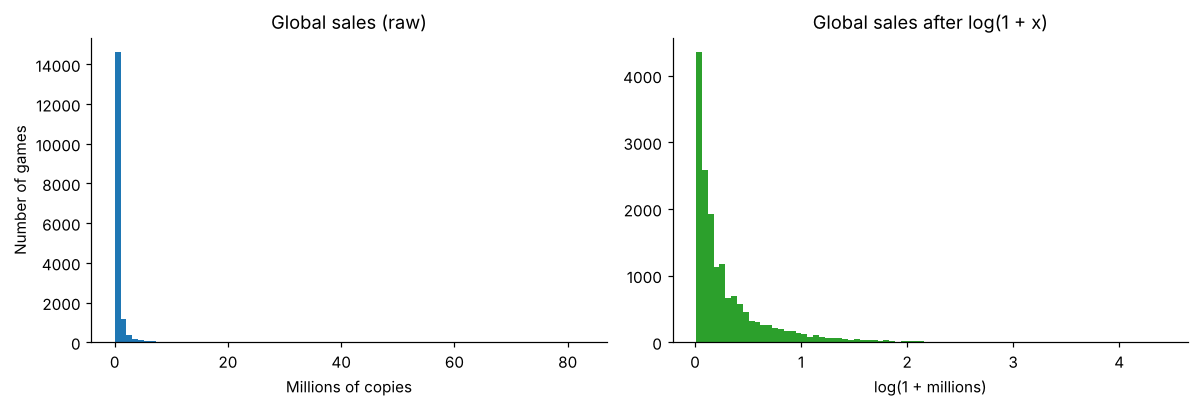

Skewness raw: 17.4  |  after log1p: 2.7


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["Global_Sales"], bins=80, color="C0")
axes[0].set(title="Global sales (raw)", xlabel="Millions of copies", ylabel="Number of games")
axes[1].hist(np.log1p(df["Global_Sales"]), bins=80, color="C2")
axes[1].set(title="Global sales after log(1 + x)", xlabel="log(1 + millions)")
plt.tight_layout(); save(fig, "01_log_transform.png"); plt.show()

print(f"Skewness raw: {df['Global_Sales'].skew():.1f}  |  after log1p: {np.log1p(df['Global_Sales']).skew():.1f}")

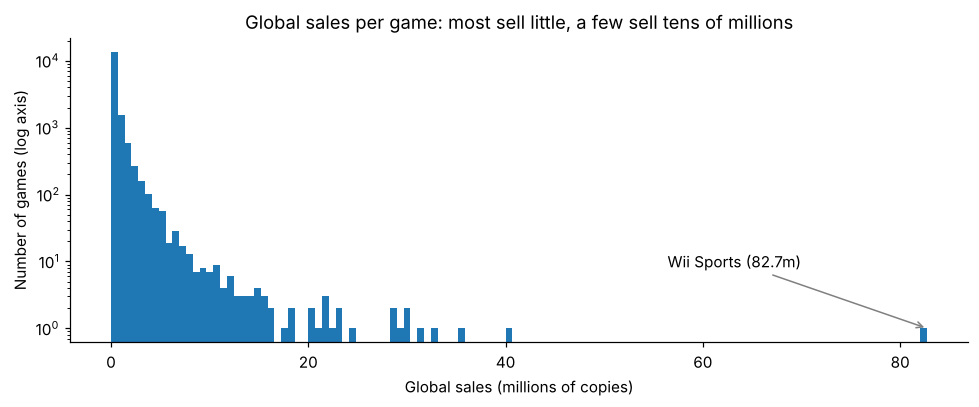

In [4]:
# Single-panel version for the slide (one visual per slide)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(df["Global_Sales"], bins=120, color="C0")
ax.set_yscale("log")
ax.set(title="Global sales per game: most sell little, a few sell tens of millions",
       xlabel="Global sales (millions of copies)", ylabel="Number of games (log axis)")
top = df.loc[df["Global_Sales"].idxmax()]
ax.annotate(f"{top['Name']} ({top['Global_Sales']:.1f}m)", (top["Global_Sales"], 1), xytext=(-170, 40),
            textcoords="offset points", arrowprops=dict(arrowstyle="->", color="grey"))
plt.tight_layout(); save(fig, "01b_raw_sales_skew.png"); plt.show()

## 3. One shared train/test split
80/20, `random_state=42`. Both research questions use the **same rows** for training and testing, so results are comparable. The test set is not used again until the final evaluation of each RQ.

In [5]:
train_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()
print("Training games:", len(train), "| Test games:", len(test))

Training games: 13273 | Test games: 3319


## 4. Helper functions

In [6]:
def millions_metrics(y_true_log, y_pred_log):
    """Metrics on the log scale (what the model optimises) and back in millions of copies (what people understand)."""
    yt, yp = np.expm1(y_true_log), np.clip(np.expm1(y_pred_log), 0, None)
    return {
        "R² (log scale)": r2_score(y_true_log, y_pred_log),
        "RMSE (log scale)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE (millions)": mean_absolute_error(yt, yp),
        "Median abs error (millions)": np.median(np.abs(yt - yp)),
    }

def compare_models(models, X, y, cv=KF):
    """Tune each model with a small grid using 5-fold CV on TRAINING data only.
    Returns a results table and the fitted (refit-on-all-training) searches."""
    rows, fitted = [], {}
    for name, (pipe, grid) in models.items():
        search = GridSearchCV(pipe, grid, cv=cv, scoring="r2", return_train_score=True, n_jobs=-1)
        search.fit(X, y)
        i = search.best_index_
        rows.append({
            "Model": name,
            "Best settings": {k.split("__")[-1]: v for k, v in search.best_params_.items()} or "-",
            "Train R² (CV)": search.cv_results_["mean_train_score"][i],
            "Validation R² (CV)": search.cv_results_["mean_test_score"][i],
            "± SD": search.cv_results_["std_test_score"][i],
        })
        fitted[name] = search
    table = pd.DataFrame(rows).set_index("Model")
    table["Gap (train − val)"] = table["Train R² (CV)"] - table["Validation R² (CV)"]
    return table.round(3), fitted

def cv_bar(table, title, fname):
    fig, ax = plt.subplots(figsize=(8, 3.6))
    t = table.sort_values("Validation R² (CV)")
    ax.barh(t.index, t["Validation R² (CV)"], xerr=t["± SD"], color="C0", alpha=.85)
    ax.axvline(0, color="grey", lw=1)
    ax.set(xlabel="Validation R² (5-fold CV, log scale)", title=title)
    for y, (v, sd) in enumerate(zip(t["Validation R² (CV)"], t["± SD"])):
        ax.text(max(v, 0) + sd + 0.01, y, f"{v:.2f}", va="center")
    ax.set_xlim(right=t["Validation R² (CV)"].max() + t["± SD"].max() + 0.08)
    plt.tight_layout(); save(fig, fname); plt.show()

## 5. RQ1 — Can we predict global sales from genre and publisher?
`log1p(Global_Sales)`  ·  **Features:** `Genre`, `Publisher`

Rare publishers are grouped into one "infrequent" category: any publisher with fewer than 20 training games. This was another thing we mentioned in the first presentation. It turns about 600 publishers into a manageable number of columns, and unseen publishers in the test set fall into that group too.

We deliberately do not use the regional sales columns as they add up to Global_Sales, so that would be leakage.

In [7]:
RQ1_FEATURES = ["Genre", "Publisher"]
y1_train, y1_test = np.log1p(train["Global_Sales"]), np.log1p(test["Global_Sales"])
X1_train, X1_test = train[RQ1_FEATURES], test[RQ1_FEATURES]

def rq1_preprocessor(cat_cols=("Genre", "Publisher"), numeric=(), min_freq=20):
    parts = [("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False)),
    ]), list(cat_cols))]
    if numeric:
        parts.append(("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), list(numeric)))
    return ColumnTransformer(parts)

n_cols = rq1_preprocessor().fit(X1_train).transform(X1_train).shape[1]
print("Columns after one-hot encoding (rare publishers grouped):", n_cols)

Columns after one-hot encoding (rare publishers grouped): 92


### 5a. Compare models with 5-fold cross-validation (training data only)
| Model | Why it's here |
|---|---|
| Baseline (mean) | Any real model must beat this |
| Linear regression | Simple, interpretable starting point (Week 5) |
| Ridge / Lasso | Regularised linear models; Lasso can switch off useless publishers (Week 7B) |
| Decision tree | Non-linear, but can overfit (Week 7A) |
| Random forest | Averages many trees to reduce overfitting (Week 8) |

In [8]:
def rq1_models():
    pre = rq1_preprocessor
    return {
        "Baseline (mean)":   (Pipeline([("pre", pre()), ("model", DummyRegressor())]), {}),
        "Linear regression": (Pipeline([("pre", pre()), ("model", LinearRegression())]), {}),
        "Ridge":             (Pipeline([("pre", pre()), ("model", Ridge())]), {"model__alpha": [0.1, 1, 10, 100]}),
        "Lasso":             (Pipeline([("pre", pre()), ("model", Lasso(max_iter=5000))]), {"model__alpha": [0.0003, 0.001, 0.003, 0.01]}),
        "Decision tree":     (Pipeline([("pre", pre()), ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
                              {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [1, 10, 30]}),
        "Random forest":     (Pipeline([("pre", pre()), ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))]),
                              {"model__min_samples_leaf": [1, 5, 20], "model__max_features": [1.0, 0.3]}),
    }

rq1_table, rq1_fitted = compare_models(rq1_models(), X1_train, y1_train)
rq1_table

,Best settings,Train R² (CV),Validation R² (CV),± SD,Gap (train − val)
Model,,,,,
Baseline (mean),-,0.000,-0.000,0.000,0.000
Linear regression,-,0.210,0.200,0.019,0.010
Ridge,{'alpha': 1},0.210,0.200,0.019,0.010
Lasso,{'alpha': 0.0003},0.204,0.195,0.017,0.009
Decision tree,"{'max_depth': None, 'min_samples_leaf': 10}",0.268,0.230,0.021,0.038
Random forest,"{'max_features': 1.0, 'min_samples_leaf': 5}",0.274,0.234,0.021,0.040


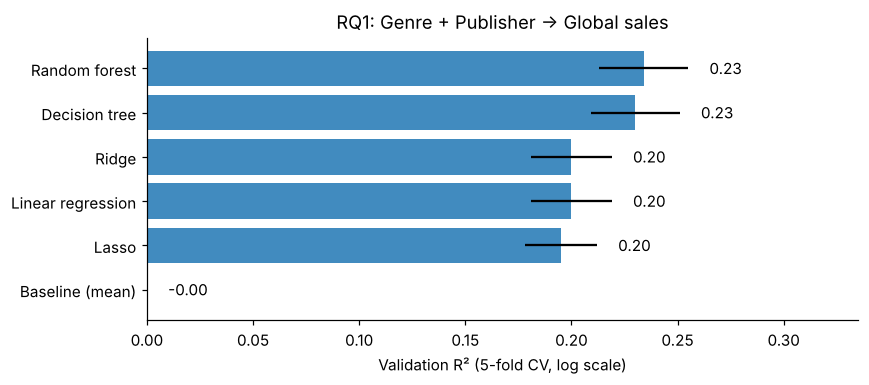

In [9]:
cv_bar(rq1_table, "RQ1: Genre + Publisher → Global sales", "02_rq1_cv_comparison.png")

### 5b. Model complexity: decision-tree depth (overfitting picture)
With only Genre and Publisher, a tree can't memorise much: there are only so many genre × publisher combinations.  this sweep uses the richer feature by adding Platform and Year.

As depth grows, training R² keeps rising. Validation R² peaks and then falls. The depth at the peak is the sweet spot; beyond it the tree is memorising training games.

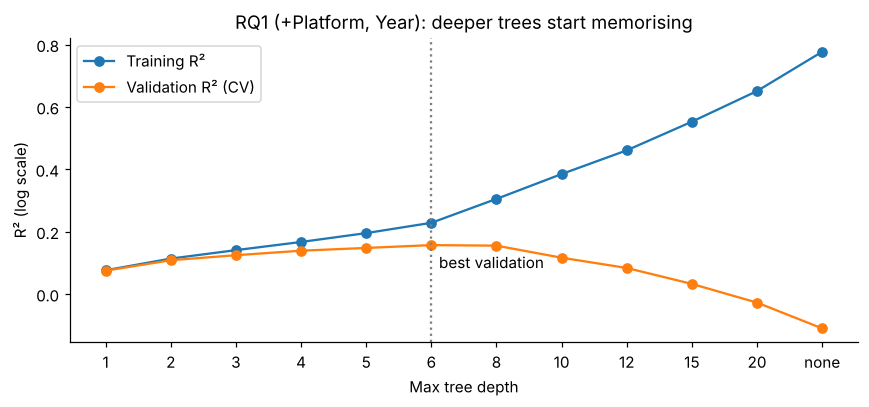

In [10]:
EXT_CAT = ("Genre", "Publisher", "Platform")
X1x_train, X1x_test = train[["Genre", "Publisher", "Platform", "Year"]], test[["Genre", "Publisher", "Platform", "Year"]]

depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
tr, va = [], []
for d in depths:
    pipe = Pipeline([("pre", rq1_preprocessor(cat_cols=EXT_CAT, numeric=["Year"])), ("model", DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))])
    s = cross_validate(pipe, X1x_train, y1_train, cv=KF, scoring="r2", return_train_score=True, n_jobs=-1)
    tr.append(s["train_score"].mean()); va.append(s["test_score"].mean())

labels = [str(d) if d else "none" for d in depths]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(labels, tr, "o-", label="Training R²")
ax.plot(labels, va, "o-", label="Validation R² (CV)")
ax.set(xlabel="Max tree depth", ylabel="R² (log scale)", title="RQ1 (+Platform, Year): deeper trees start memorising")
best_d = int(np.argmax(va)); ax.axvline(best_d, ls=":", color="grey"); ax.annotate("best validation", (best_d, va[best_d]), xytext=(5, -15), textcoords="offset points")
ax.legend(); plt.tight_layout(); save(fig, "03_rq1_tree_depth.png"); plt.show()

### 5c. Does adding Platform and Year help? (extension)
Our RQ is about genre and publisher, but it's worth showing how much more two extra features add.

In [11]:
ext_models = {
    "Baseline (mean)": (Pipeline([("pre", rq1_preprocessor(cat_cols=EXT_CAT, numeric=["Year"])), ("model", DummyRegressor())]), {}),
    "Ridge (+Platform, Year)": (Pipeline([("pre", rq1_preprocessor(cat_cols=EXT_CAT, numeric=["Year"])), ("model", Ridge())]), {"model__alpha": [1, 10, 100]}),
    "Random forest (+Platform, Year)": (Pipeline([("pre", rq1_preprocessor(cat_cols=EXT_CAT, numeric=["Year"])),
                                         ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))]),
                                        {"model__min_samples_leaf": [5, 20], "model__max_features": [1.0, 0.3]}),
}
rq1x_table, rq1x_fitted = compare_models(ext_models, X1x_train, y1_train)
rq1x_table

,Best settings,Train R² (CV),Validation R² (CV),± SD,Gap (train − val)
Model,,,,,
Baseline (mean),-,0.000,-0.000,0.000,0.000
"Ridge (+Platform, Year)",{'alpha': 1},0.273,0.261,0.024,0.012
"Random forest (+Platform, Year)","{'max_features': 0.3, 'min_samples_leaf': 5}",0.421,0.308,0.016,0.112


### 5d. Final evaluation on the test set (used once)
We pick the model with the best **validation** R² from 5a. Then, and only then, we score it on the test set.

In [12]:
best1_name = rq1_table.drop(index="Baseline (mean)")["Validation R² (CV)"].idxmax()
best1 = rq1_fitted[best1_name].best_estimator_
base1 = rq1_fitted["Baseline (mean)"].best_estimator_
print("Chosen RQ1 model:", best1_name)

pred1 = best1.predict(X1_test)
rq1_test = pd.DataFrame({
    "Baseline (mean)": millions_metrics(y1_test, base1.predict(X1_test)),
    best1_name: millions_metrics(y1_test, pred1),
}).round(3)
rq1_test

Chosen RQ1 model: Random forest


,Baseline (mean),Random forest
R² (log scale),-0.000,0.230
RMSE (log scale),0.409,0.359
MAE (millions),0.540,0.485
Median abs error (millions),0.278,0.185


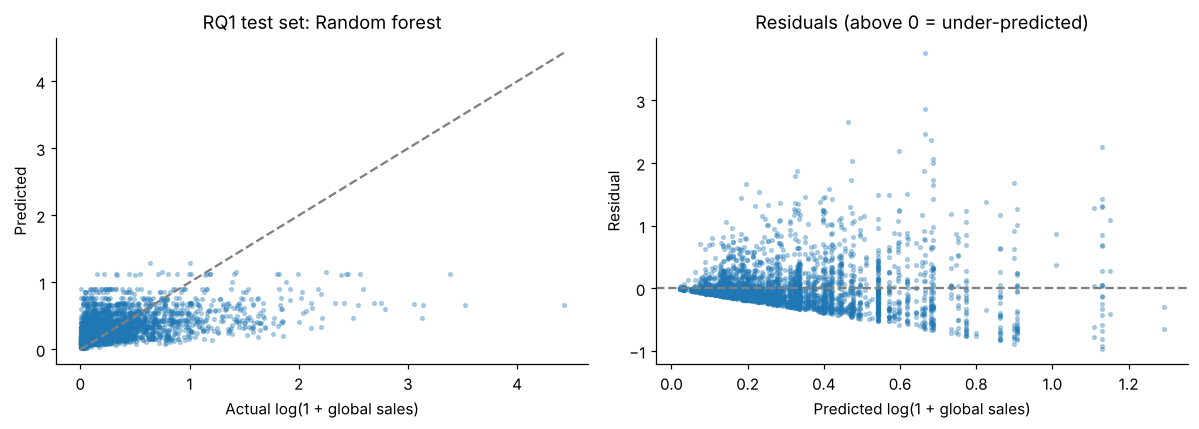

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y1_test, pred1, s=6, alpha=.3)
lim = [0, max(y1_test.max(), pred1.max())]
axes[0].plot(lim, lim, "--", color="grey")
axes[0].set(xlabel="Actual log(1 + global sales)", ylabel="Predicted", title=f"RQ1 test set: {best1_name}")
res = y1_test - pred1
axes[1].scatter(pred1, res, s=6, alpha=.3)
axes[1].axhline(0, ls="--", color="grey")
axes[1].set(xlabel="Predicted log(1 + global sales)", ylabel="Residual", title="Residuals (above 0 = under-predicted)")
plt.tight_layout(); save(fig, "04_rq1_pred_vs_actual.png"); plt.show()

### 5e. Interpretation: what drives the predictions?
First, **random forest importances**: which columns the forest leans on.
Second, **Ridge coefficients**: the direction of each effect.

On a log scale, a Ridge coefficient *b* means roughly ×e^b in sales (1 + sales, strictly).

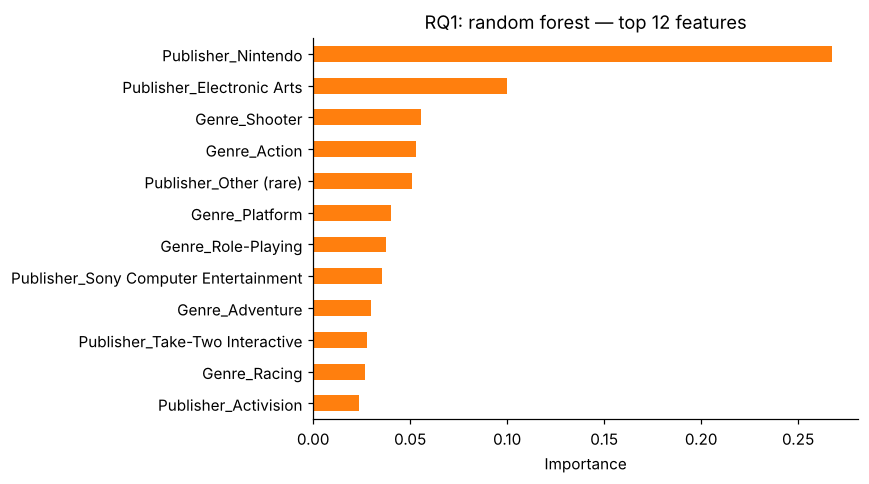

Share of importance from Genre columns: 32%  |  from Publisher columns: 68%


In [14]:
rf1 = rq1_fitted["Random forest"].best_estimator_
names = rf1.named_steps["pre"].get_feature_names_out()
names = [n.replace("cat__", "").replace("infrequent_sklearn", "Other (rare)") for n in names]
imp = pd.Series(rf1.named_steps["model"].feature_importances_, index=names).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
imp.tail(12).plot.barh(ax=ax, color="C1")
ax.set(title="RQ1: random forest — top 12 features", xlabel="Importance")
plt.tight_layout(); save(fig, "05_rq1_rf_importance.png"); plt.show()

genre_share = imp[[n for n in imp.index if n.startswith("Genre_")]].sum()
print(f"Share of importance from Genre columns: {genre_share:.0%}  |  from Publisher columns: {1 - genre_share:.0%}")

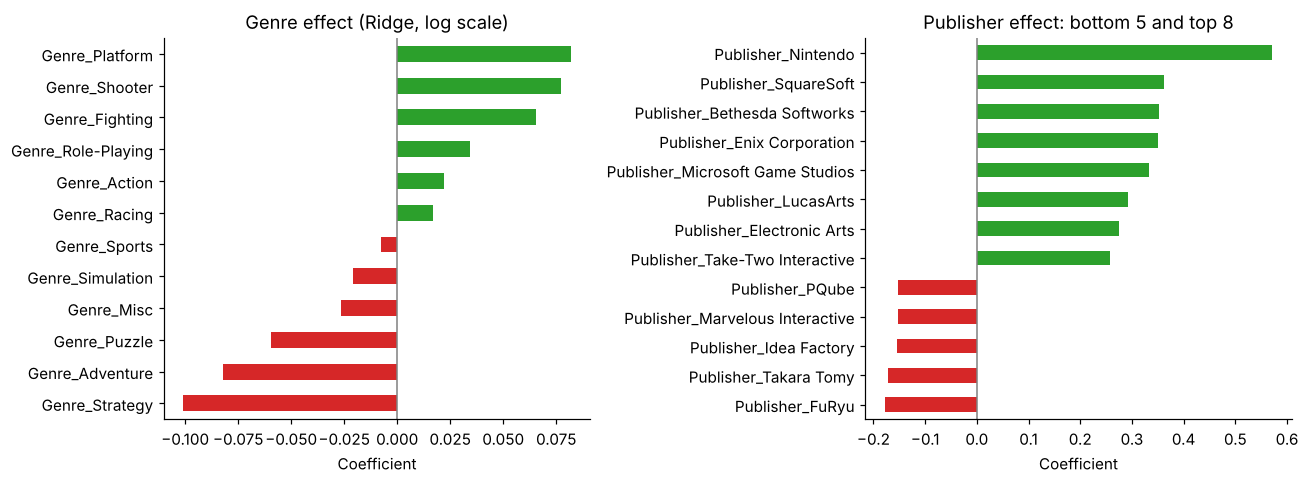

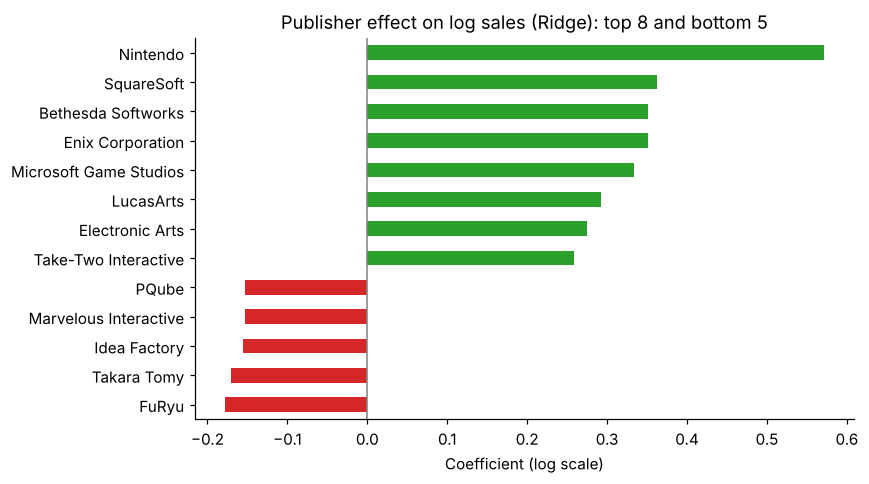

Lasso kept 50 of 92 columns


In [15]:
ridge1 = rq1_fitted["Ridge"].best_estimator_
rnames = [n.replace("cat__", "").replace("infrequent_sklearn", "Other (rare)") for n in ridge1.named_steps["pre"].get_feature_names_out()]
coefs = pd.Series(ridge1.named_steps["model"].coef_, index=rnames)

genre_c = coefs[coefs.index.str.startswith("Genre_")].sort_values()
pub_c = coefs[coefs.index.str.startswith("Publisher_")].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
genre_c.plot.barh(ax=axes[0], color=np.where(genre_c > 0, "C2", "C3"))
axes[0].set(title="Genre effect (Ridge, log scale)", xlabel="Coefficient")
pd.concat([pub_c.head(5), pub_c.tail(8)]).plot.barh(ax=axes[1], color=np.where(pd.concat([pub_c.head(5), pub_c.tail(8)]) > 0, "C2", "C3"))
axes[1].set(title="Publisher effect: bottom 5 and top 8", xlabel="Coefficient")
for a in axes: a.axvline(0, color="grey", lw=1)
plt.tight_layout(); save(fig, "06_rq1_ridge_coefficients.png"); plt.show()

# Single-panel version for the slide (one visual per slide): publishers only
pub_sel = pd.concat([pub_c.head(5), pub_c.tail(8)])
pub_sel.index = pub_sel.index.str.replace("Publisher_", "", regex=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
pub_sel.plot.barh(ax=ax, color=np.where(pub_sel > 0, "C2", "C3"))
ax.axvline(0, color="grey", lw=1)
ax.set(title="Publisher effect on log sales (Ridge): top 8 and bottom 5", xlabel="Coefficient (log scale)")
plt.tight_layout(); save(fig, "06b_rq1_publisher_effects.png"); plt.show()

lasso1 = rq1_fitted["Lasso"].best_estimator_
print("Lasso kept", int((lasso1.named_steps["model"].coef_ != 0).sum()), "of", len(lasso1.named_steps["model"].coef_), "columns")

### 5f. Example predictions (for the 'Predictions' slide)

In [16]:
def example_table(test_df, pred_log, actual_col, n_each=2):
    out = test_df[["Name", "Platform", "Genre", "Publisher"]].copy()
    out["Actual (m)"] = test_df[actual_col].values
    out["Predicted (m)"] = np.clip(np.expm1(pred_log), 0, None).round(2)
    out["Error (m)"] = (out["Actual (m)"] - out["Predicted (m)"]).round(2)
    out = out.sort_values("Actual (m)", ascending=False)
    typical = out[(out["Actual (m)"] > 0.1) & (out["Actual (m)"] < 1)].sample(n_each + 1, random_state=1)
    return pd.concat([out.head(n_each), typical]).reset_index(drop=True)

rq1_examples = example_table(test, pred1, "Global_Sales")
rq1_examples

,Name,Platform,Genre,Publisher,Actual (m),Predicted (m),Error (m)
0,Wii Sports,WII,Sports,Nintendo,82.74,0.95,81.79
1,Wii Sports Resort,WII,Sports,Nintendo,33.00,0.95,32.05
2,Scooby-Doo! and the Spooky Swamp,DS,Action,Warner Bros. Interactive Entertainment,0.40,0.56,-0.16
3,Irozuki Tingle no Koi no Balloon Trip,DS,Adventure,Nintendo,0.11,0.60,-0.49
4,We Sing,WII,Misc,Nordic Games,0.78,0.15,0.63


## 6. RQ2 — Can we predict NA sales from EU and JP sales?
`log1p(NA_Sales)`  ·  **Features:** `log1p(EU_Sales)`, `log1p(JP_Sales)`

### 6a. First: redo the first presentation's model on the raw scale vs the log scale
In Presentation I, test R² was 0.79 but training R² was about 0.52, because Wii Sports landed in the test set. Here we check whether the log transform fixes that gap.

R² on the raw and log scales measure different things, so compare the **train/test gap**, not the raw numbers.

In [17]:
y2_train_raw, y2_test_raw = train["NA_Sales"], test["NA_Sales"]
y2_train, y2_test = np.log1p(y2_train_raw), np.log1p(y2_test_raw)

rows = []
for feats in (["EU_Sales"], ["EU_Sales", "JP_Sales"]):
    raw = LinearRegression().fit(train[feats], y2_train_raw)
    logm = LinearRegression().fit(np.log1p(train[feats]), y2_train)
    rows.append({"Features": " + ".join(f[:2] for f in feats),
                 "Raw: train R²": raw.score(train[feats], y2_train_raw), "Raw: test R²": raw.score(test[feats], y2_test_raw),
                 "Log: train R²": logm.score(np.log1p(train[feats]), y2_train), "Log: test R²": logm.score(np.log1p(test[feats]), y2_test)})
raw_vs_log = pd.DataFrame(rows).set_index("Features").round(3)
raw_vs_log

,Raw: train R²,Raw: test R²,Log: train R²,Log: test R²
Features,,,,
EU,0.493,0.788,0.576,0.623
EU + JP,0.523,0.770,0.581,0.625


### 6b. Compare models with 5-fold CV (training data only)

In [18]:
log_tf = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
X2_train, X2_test = train[["EU_Sales", "JP_Sales"]], test[["EU_Sales", "JP_Sales"]]

def eu_only():
    return ColumnTransformer([("log", log_tf, ["EU_Sales"])])
def eu_jp():
    return ColumnTransformer([("log", log_tf, ["EU_Sales", "JP_Sales"])])

rq2_models = {
    "Baseline (mean)":          (Pipeline([("pre", eu_jp()), ("model", DummyRegressor())]), {}),
    "Linear: EU only":          (Pipeline([("pre", eu_only()), ("model", LinearRegression())]), {}),
    "Linear: EU + JP":          (Pipeline([("pre", eu_jp()), ("model", LinearRegression())]), {}),
    "Decision tree: EU + JP":   (Pipeline([("pre", eu_jp()), ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
                                 {"model__max_depth": [2, 4, 6, 8, None], "model__min_samples_leaf": [1, 20, 50]}),
    "Random forest: EU + JP":   (Pipeline([("pre", eu_jp()), ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))]),
                                 {"model__min_samples_leaf": [5, 20, 50]}),
}
rq2_table, rq2_fitted = compare_models(rq2_models, X2_train, y2_train)
rq2_table

,Best settings,Train R² (CV),Validation R² (CV),± SD,Gap (train − val)
Model,,,,,
Baseline (mean),-,0.000,-0.000,0.000,0.000
Linear: EU only,-,0.576,0.575,0.026,0.001
Linear: EU + JP,-,0.581,0.579,0.026,0.002
Decision tree: EU + JP,"{'max_depth': 6, 'min_samples_leaf': 20}",0.623,0.591,0.027,0.033
Random forest: EU + JP,{'min_samples_leaf': 20},0.629,0.596,0.026,0.033


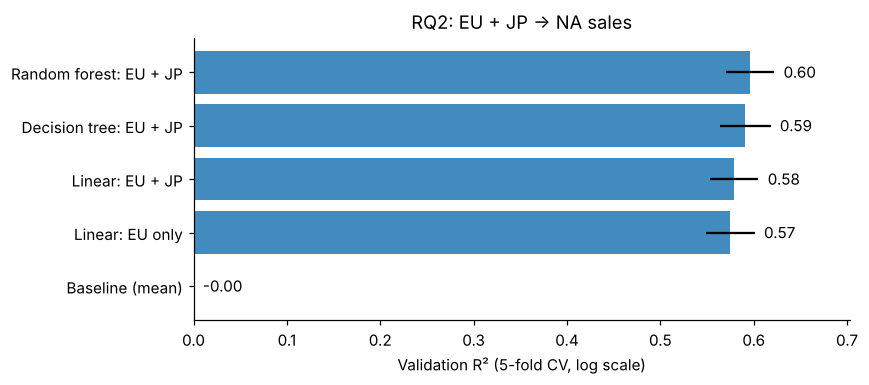

In [19]:
cv_bar(rq2_table, "RQ2: EU + JP → NA sales", "07_rq2_cv_comparison.png")

### 6c. Why do so many games have NA = 0 but EU > 0? (and Japan-only games)
Zeros are the hardest cases for a straight line so we count them.

In [20]:
zero_na = (df["NA_Sales"] == 0)
print(f"Games with 0 NA sales: {zero_na.mean():.0%}")
print(f"  of these, sold in Japan: {(zero_na & (df['JP_Sales'] > 0)).sum() / zero_na.sum():.0%}")
jp_only = (df["JP_Sales"] > 0) & (df["NA_Sales"] == 0) & (df["EU_Sales"] == 0)
print(f"Japan-only games (JP > 0, NA = EU = 0): {jp_only.sum()} ({jp_only.mean():.0%} of all games)")

Games with 0 NA sales: 27%
  of these, sold in Japan: 77%
Japan-only games (JP > 0, NA = EU = 0): 3372 (20% of all games)


### 6d. Final evaluation on the test set (used once)

In [21]:
best2_name = rq2_table.drop(index="Baseline (mean)")["Validation R² (CV)"].idxmax()
best2 = rq2_fitted[best2_name].best_estimator_
simple2 = rq2_fitted["Linear: EU only"].best_estimator_
base2 = rq2_fitted["Baseline (mean)"].best_estimator_
print("Best RQ2 model by CV:", best2_name)

pred2 = best2.predict(X2_test)
pred2_simple = simple2.predict(X2_test)
rq2_test = pd.DataFrame({
    "Baseline (mean)": millions_metrics(y2_test, base2.predict(X2_test)),
    "Linear: EU only": millions_metrics(y2_test, pred2_simple),
    best2_name: millions_metrics(y2_test, pred2),
}).round(3)
rq2_test

Best RQ2 model by CV: Random forest: EU + JP


,Baseline (mean),Linear: EU only,Random forest: EU + JP
R² (log scale),-0.000,0.623,0.639
RMSE (log scale),0.293,0.180,0.176
MAE (millions),0.288,0.178,0.177
Median abs error (millions),0.171,0.073,0.064


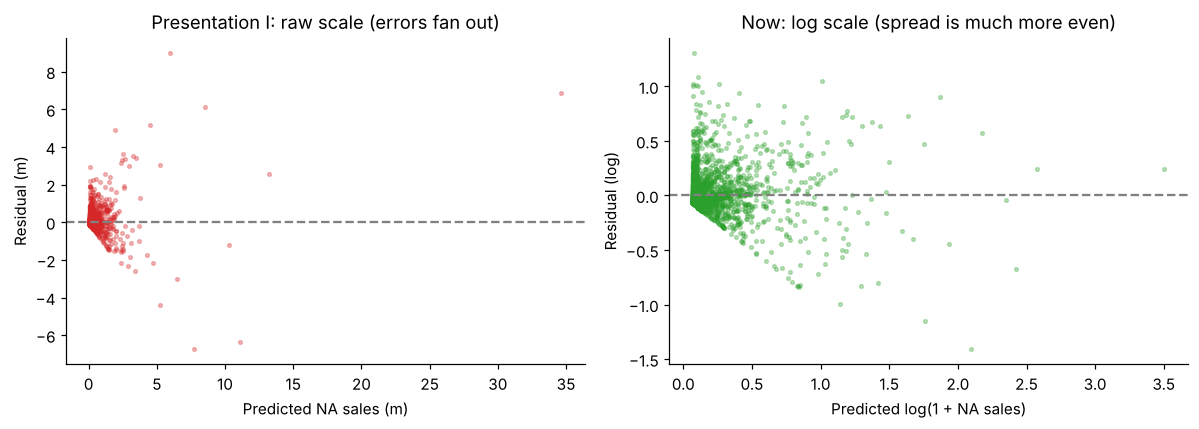

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw = LinearRegression().fit(train[["EU_Sales"]], y2_train_raw)
p_raw = raw.predict(test[["EU_Sales"]])
axes[0].scatter(p_raw, y2_test_raw - p_raw, s=6, alpha=.3, color="C3")
axes[0].axhline(0, ls="--", color="grey")
axes[0].set(title="Presentation I: raw scale (errors fan out)", xlabel="Predicted NA sales (m)", ylabel="Residual (m)")
axes[1].scatter(pred2_simple, y2_test - pred2_simple, s=6, alpha=.3, color="C2")
axes[1].axhline(0, ls="--", color="grey")
axes[1].set(title="Now: log scale (spread is much more even)", xlabel="Predicted log(1 + NA sales)", ylabel="Residual (log)")
plt.tight_layout(); save(fig, "08_rq2_residuals_raw_vs_log.png"); plt.show()

### 6e. Interpretation of the log–log linear model
With both sides logged: For Europe a 1% rise in (1 + EU sales) goes with about *b*% higher (1 + NA sales). The JP coefficient tells us whether Japan adds anything once we know EU.

In [23]:
lin2 = rq2_fitted["Linear: EU + JP"].best_estimator_.named_steps["model"]
lin2_eu = simple2.named_steps["model"]
print(f"EU only : log1p(NA) = {lin2_eu.intercept_:.3f} + {lin2_eu.coef_[0]:.3f} × log1p(EU)")
print(f"EU + JP : log1p(NA) = {lin2.intercept_:.3f} + {lin2.coef_[0]:.3f} × log1p(EU) + {lin2.coef_[1]:.3f} × log1p(JP)")
print()
print(f"Correlation with log NA — EU: {np.corrcoef(np.log1p(df.EU_Sales), np.log1p(df.NA_Sales))[0,1]:.2f}, "
      f"JP: {np.corrcoef(np.log1p(df.JP_Sales), np.log1p(df.NA_Sales))[0,1]:.2f}")

EU only : log1p(NA) = 0.071 + 1.009 × log1p(EU)
EU + JP : log1p(NA) = 0.067 + 0.981 × log1p(EU) + 0.118 × log1p(JP)

Correlation with log NA — EU: 0.77, JP: 0.30


### 6f. Example predictions

In [24]:
rq2_examples = example_table(test, pred2, "NA_Sales")
rq2_examples.insert(4, "EU (m)", test.set_index("Name").loc[rq2_examples["Name"], "EU_Sales"].groupby(level=0).first().reindex(rq2_examples["Name"]).values)
rq2_examples

,Name,Platform,Genre,Publisher,EU (m),Actual (m),Predicted (m),Error (m)
0,Wii Sports,WII,Sports,Nintendo,29.02,41.49,6.16,35.33
1,Wii Sports Resort,WII,Sports,Nintendo,11.01,15.75,6.16,9.59
2,Bully: Scholarship Edition,WII,Action,Take-Two Interactive,0.29,0.17,0.35,-0.18
3,Suikoden II,PS,Role-Playing,Konami Digital Entertainment,0.10,0.15,0.25,-0.10
4,Trauma Center: Under the Knife,DS,Simulation,Nintendo,0.01,0.30,0.12,0.18


## 9.extensions — neural network (MLP) and K-means clustering
Two methods from the final lectyure, kept in their own section so the chosen models and test results above do not change.

**9a. Neural network (MLPRegressor).** Same features, same 5 CV folds, training data only. Inputs are standardised (neural networks need it) and `early_stopping=True` holds back 10% of each training fold to stop training before the network overfits.

In [27]:
from sklearn.neural_network import MLPRegressor

def mlp(**kw):
    return MLPRegressor(early_stopping=True, max_iter=1000, random_state=RANDOM_STATE, **kw)

MLP_GRID = {"model__hidden_layer_sizes": [(12,), (32, 16)], "model__alpha": [1e-4, 1e-2]}

mlp_rq1 = {"Neural network (MLP)": (Pipeline([("pre", rq1_preprocessor()), ("model", mlp())]), MLP_GRID)}
mlp_rq2 = {"Neural network (MLP): EU + JP": (Pipeline([("pre", eu_jp()), ("scale", StandardScaler()), ("model", mlp())]), MLP_GRID)}

mlp1_table, _ = compare_models(mlp_rq1, X1_train, y1_train)
mlp2_table, _ = compare_models(mlp_rq2, X2_train, y2_train)

week9_compare = pd.DataFrame({
    "RQ1 validation R² (CV)": {"Random forest": rq1_table.loc["Random forest", "Validation R² (CV)"],
                                "Neural network (MLP)": mlp1_table.iloc[0]["Validation R² (CV)"]},
    "RQ2 validation R² (CV)": {"Random forest": rq2_table.loc["Random forest: EU + JP", "Validation R² (CV)"],
                                "Neural network (MLP)": mlp2_table.iloc[0]["Validation R² (CV)"]},
}).round(3)
display(pd.concat([mlp1_table, mlp2_table]))
week9_compare

,Best settings,Train R² (CV),Validation R² (CV),± SD,Gap (train − val)
Model,,,,,
Neural network (MLP),"{'alpha': 0.0001, 'hidden_layer_sizes': (32, 16)}",0.270,0.232,0.022,0.039
Neural network (MLP): EU + JP,"{'alpha': 0.0001, 'hidden_layer_sizes': (32, 16)}",0.611,0.605,0.026,0.006


,RQ1 validation R² (CV),RQ2 validation R² (CV)
Random forest,0.234,0.596
Neural network (MLP),0.232,0.605



### 9b. K-means: what kinds of market does a game have?
Unsupervised (no target). Each game is described by its **share** of sales in each region (NA, EU, JP, Other — they add to 1), so clusters group games by *where* they sell, not *how much*. We drop games under 0.1m global copies because their shares are dominated by rounding (0.01m steps). Shares are standardised, then K-means with k-means++ and `n_init=20`.

Games clustered: 10817


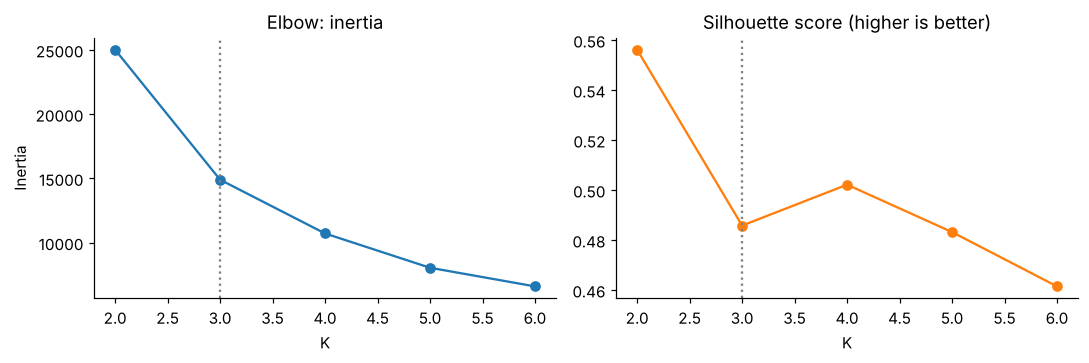

,Inertia,Silhouette
K,,
2,25011.829,0.556
3,14896.266,0.486
4,10713.986,0.502
5,8045.610,0.483
6,6595.104,0.461


In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

REG = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
km_df = df[df["Global_Sales"] >= 0.1].copy()
shares = km_df[REG].div(km_df[REG].sum(axis=1), axis=0)
shares.columns = ["NA", "EU", "JP", "Other"]
Xk = StandardScaler().fit_transform(shares)
print("Games clustered:", len(km_df))

ks, inertia, sil = range(2, 7), [], []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=RANDOM_STATE).fit(Xk)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xk, km.labels_, sample_size=5000, random_state=RANDOM_STATE))
choose_k = pd.DataFrame({"Inertia": inertia, "Silhouette": sil}, index=pd.Index(ks, name="K")).round(3)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set(title="Elbow: inertia", xlabel="K", ylabel="Inertia")
axes[1].plot(list(ks), sil, "o-", color="C1"); axes[1].set(title="Silhouette score (higher is better)", xlabel="K")
for ax in axes: ax.axvline(3, ls=":", color="grey")
plt.tight_layout(); save(fig, "10_kmeans_choose_k.png"); plt.show()
choose_k

**Choosing K is a judgement call.** The silhouette score is highest at K = 2 (it splits "Japan" from "everything else"), while the elbow bends at around K = 3–4. We use **K = 3** because it separates two different Western profiles and each cluster has a clear, explainable meaning.

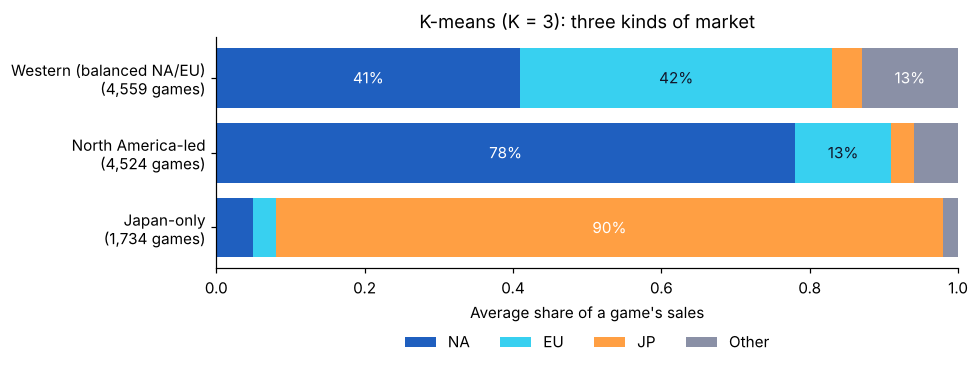

,NA,EU,JP,Other,Games,Median global sales (m),Top genres
cluster,,,,,,,
Western (balanced NA/EU),0.41,0.42,0.04,0.13,4559,0.46,"Action, Sports, Shooter"
North America-led,0.78,0.13,0.03,0.06,4524,0.29,"Action, Sports, Misc"
Japan-only,0.05,0.03,0.90,0.02,1734,0.26,"Role-Playing, Sports, Action"


In [29]:
K = 3
km3 = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=RANDOM_STATE).fit(Xk)
km_df["cluster"] = km3.labels_
prof = shares.groupby(km_df["cluster"]).mean()

def name_cluster(r):
    if r["JP"] > 0.5: return "Japan-only"
    if r["NA"] > 0.6: return "North America-led"
    return "Western (balanced NA/EU)"
names = prof.apply(name_cluster, axis=1)
km_df["Market"] = km_df["cluster"].map(names)

cluster_table = prof.rename(index=names).round(2)
cluster_table["Games"] = km_df["Market"].value_counts()
cluster_table["Median global sales (m)"] = km_df.groupby("Market")["Global_Sales"].median()
cluster_table["Top genres"] = km_df.groupby("Market")["Genre"].agg(lambda s: ", ".join(s.value_counts().index[:3]))
order = ["Western (balanced NA/EU)", "North America-led", "Japan-only"]
cluster_table = cluster_table.loc[order]

colors = {"NA": "#1F5FBF", "EU": "#38D0F0", "JP": "#FF9F43", "Other": "#8A90A6"}
fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(order))
for reg in ["NA", "EU", "JP", "Other"]:
    v = cluster_table[reg].values
    ax.barh(order, v, left=left, color=colors[reg], label=reg)
    for i, (l, w) in enumerate(zip(left, v)):
        if w > 0.07: ax.text(l + w / 2, i, f"{w:.0%}", ha="center", va="center", color="white" if reg != "EU" else "#12162A", fontsize=10)
    left += v
ax.set_yticks(range(len(order)), [f"{m}\n({n:,} games)" for m, n in zip(order, cluster_table["Games"])])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Average share of a game's sales")
ax.set_title("K-means (K = 3): three kinds of market")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
plt.tight_layout(); save(fig, "11_kmeans_clusters.png"); plt.show()
cluster_table

**What it tells us:** most games are Western, either balanced between North America and Europe or led by North America. A separate block of about 1 in 6 games sells almost only in Japan, and it is dominated by role-playing games. This is why Japanese sales add so little to RQ2: for these games, knowing JP sales tells you NA sales are near zero.

## 8. Summary for our powerpoint slides


In [30]:
summary = pd.DataFrame({
    "RQ1 (Genre + Publisher → Global)": {
        "Chosen model": best1_name,
        "Validation R² (CV)": rq1_table.loc[best1_name, "Validation R² (CV)"],
        "Test R² (log)": rq1_test.loc["R² (log scale)", best1_name],
        "Test MAE (m)": rq1_test.loc["MAE (millions)", best1_name],
        "Baseline test MAE (m)": rq1_test.loc["MAE (millions)", "Baseline (mean)"],
    },
    "RQ2 (EU + JP → NA)": {
        "Chosen model": best2_name,
        "Validation R² (CV)": rq2_table.loc[best2_name, "Validation R² (CV)"],
        "Test R² (log)": rq2_test.loc["R² (log scale)", best2_name],
        "Test MAE (m)": rq2_test.loc["MAE (millions)", best2_name],
        "Baseline test MAE (m)": rq2_test.loc["MAE (millions)", "Baseline (mean)"],
    },
})
summary

,RQ1 (Genre + Publisher → Global),RQ2 (EU + JP → NA)
Chosen model,Random forest,Random forest: EU + JP
Validation R² (CV),0.234,0.596
Test R² (log),0.23,0.639
Test MAE (m),0.485,0.177
Baseline test MAE (m),0.54,0.288
